# Kernel Experiments

This notebook is a compact playground for GP kernel behavior. It is not part of
the thesis figure pipeline. The thesis-relevant RBF contribution decomposition
has been moved to `Ch2-0-Plots.ipynb`, where it motivates training the
cross section in log space.

The cells below are arranged so you can hit **Run All** and watch a few focused
experiments: length-scale sensitivity, kernel-family comparison, and linear vs
log observation models on one irregular synthetic curve.


In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
try:
    import scienceplots
except ModuleNotFoundError:
    scienceplots = None
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic, ConstantKernel

def find_project_root(start):
    for base in [start, *start.parents]:
        for candidate in [base, base / "barrier-extraction"]:
            if (candidate / "src").is_dir() and (candidate / "data").is_dir():
                return candidate
    raise FileNotFoundError("Could not locate barrier-extraction project root containing src/ and data/.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
PLOT_DIR = PROJECT_ROOT / "plots"
PLOT_DIR.mkdir(exist_ok=True)
EXPERIMENT_DATA_DIR = DATA_DIR / "experimental"


from src.train import barrier_from_sigma_samples
from src.utils import load_packed_hdf5
from src.wong import sigma

if scienceplots is not None:
    plt.style.use(["science", "no-latex", "ieee", "grid"])
else:
    plt.style.use("default")
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "legend.fontsize": 8,
    "figure.dpi": 140,
    "savefig.dpi": 300,
})


/opt/software-current/2023.06/x86_64/intel/skylake_avx512/software/Python-bundle-PyPI/2023.06-GCCcore-12.3.0/lib/python3.11/site-packages/pyparsing/core.py:5596: SyntaxWarning: 'return' in a 'finally' block
  return self.__class__.__name__ + ": " + retString


## Shared example curve

The experiments use one deliberately irregular synthetic dataset. Change
`DATASET_NAME` or `DATASET_INDEX` to explore another curve. The lookup checks
`BARRIER_DATASET_DIR`, `~/scratch/barrier-paper-datasets`, and local `data/` or
`data/packed/` folders.


In [2]:
DATASET_NAME = "cv0.75_spacing1.0.h5"
DATASET_INDEX = 623

def find_dataset_file(dataset_name):
    candidates = [
        Path(os.environ.get("BARRIER_DATASET_DIR", "")) / dataset_name,
        Path.home() / "scratch" / "barrier-paper-datasets" / dataset_name,
        PROJECT_ROOT / "data" / dataset_name,
        PROJECT_ROOT / "data" / "packed" / dataset_name,
    ]
    found = next((path for path in candidates if path.is_file()), None)
    if found is None:
        raise FileNotFoundError(
            f"Could not find {dataset_name}. Set BARRIER_DATASET_DIR or place it under data/packed/."
        )
    return found

DATA_PATH = find_dataset_file(DATASET_NAME)
ds = load_packed_hdf5(str(DATA_PATH))
E_train, Sigma_train, Sigma_err_train, params_true = ds["get_i"](DATASET_INDEX)
order = np.argsort(E_train)
E_train = np.asarray(E_train, float)[order]
Sigma_train = np.asarray(Sigma_train, float)[order]
Sigma_err_train = np.asarray(Sigma_err_train, float)[order]

E_pred = np.linspace(E_train.min(), E_train.max(), 500)
Sigma_true = sigma(E_pred, *params_true)
D_true = barrier_from_sigma_samples(E_pred, Sigma_true[None, :])[0]
spacing = np.diff(E_train)
print(f"Dataset: {DATA_PATH}")
print(f"N={len(E_train)}, mean spacing={spacing.mean():.3f} MeV, spacing CV={spacing.std()/spacing.mean():.3f}")


Dataset: /mnt/home/philipaa/scratch/barrier-paper-datasets/cv0.75_spacing1.0.h5
N=27, mean spacing=1.105 MeV, spacing CV=0.552


In [3]:
def moment_matched_log_observations(y, y_err):
    y = np.asarray(y, float)
    y_err = np.asarray(y_err, float)
    log_var = np.log1p((y_err / y) ** 2)
    return np.log(y) + 0.5 * log_var, log_var


def fit_gp_model(E, y, y_err, kernel, space="linear", n_restarts=4, random_state=0):
    if space == "linear":
        target = np.asarray(y, float)
        alpha = np.asarray(y_err, float) ** 2
    elif space == "log":
        if np.any(np.asarray(y) <= 0):
            raise ValueError("Log-space GP requires positive y values.")
        target, alpha = moment_matched_log_observations(y, y_err)
    else:
        raise ValueError("space must be 'linear' or 'log'")

    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=np.maximum(alpha, 1e-14),
        normalize_y=False,
        n_restarts_optimizer=n_restarts,
        random_state=random_state,
    )
    gp.fit(np.asarray(E).reshape(-1, 1), target)
    return gp


def predict_sigma(gp, x, space="linear"):
    mu, std = gp.predict(np.asarray(x).reshape(-1, 1), return_std=True)
    if space == "linear":
        return mu, mu - 1.96 * std, mu + 1.96 * std
    median = np.exp(mu)
    lo = np.exp(mu - 1.96 * std)
    hi = np.exp(mu + 1.96 * std)
    return median, lo, hi


def barrier_from_curve(y_curve):
    return barrier_from_sigma_samples(E_pred, np.asarray(y_curve)[None, :])[0]


def base_rbf(length_scale=None):
    amp = max(np.var(Sigma_train), 1e-6)
    ell0 = 2.0 * np.median(spacing) if length_scale is None else length_scale
    bounds = (max(0.05, 0.25 * np.median(spacing)), 0.75 * np.ptp(E_train))
    if length_scale is None:
        return ConstantKernel(amp, (1e-8, 1e9)) * RBF(ell0, bounds)
    return ConstantKernel(amp, "fixed") * RBF(length_scale, "fixed")


def plot_sigma_and_barrier(ax_sigma, ax_barrier, gp, label, color, space="linear"):
    mu, lo, hi = predict_sigma(gp, E_pred, space=space)
    ax_sigma.plot(E_pred, mu, color=color, lw=1.6, label=label)
    ax_sigma.fill_between(E_pred, lo, hi, color=color, alpha=0.12, linewidth=0)
    ax_barrier.plot(E_pred, barrier_from_curve(mu), color=color, lw=1.6, label=label)


## 1. RBF length-scale sensitivity

Holding the RBF length scale fixed makes the smoothing tradeoff obvious. Short
length scales follow local wiggles and create oscillatory barriers; long length
scales wash out the peak.


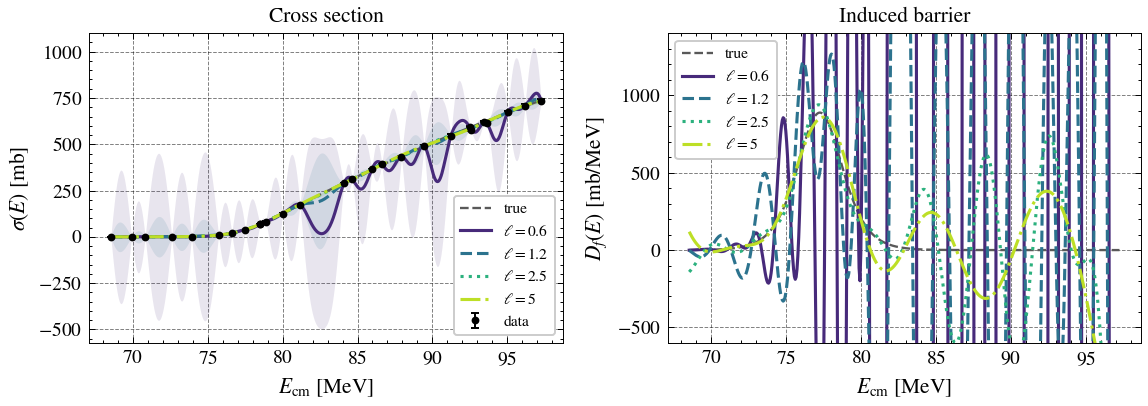

In [4]:
length_scales = [0.6, 1.2, 2.5, 5.0]
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.1), sharex=True)
colors = plt.cm.viridis(np.linspace(0.12, 0.9, len(length_scales)))

axes[0].errorbar(E_train, Sigma_train, yerr=Sigma_err_train, fmt="o", color="black", ms=3, capsize=2, label="data")
axes[0].plot(E_pred, Sigma_true, color="0.35", ls="--", lw=1.2, label="true")
axes[1].plot(E_pred, D_true, color="0.35", ls="--", lw=1.2, label="true")

for ell, color in zip(length_scales, colors):
    gp = fit_gp_model(E_train, Sigma_train, Sigma_err_train, base_rbf(ell), n_restarts=0)
    plot_sigma_and_barrier(axes[0], axes[1], gp, rf"$\ell={ell:g}$", color)

axes[0].set_title("Cross section")
axes[1].set_title("Induced barrier")
axes[0].set_ylabel(r"$\sigma(E)$ [mb]")
axes[1].set_ylabel(r"$D_f(E)$ [mb/MeV]")
for ax in axes:
    ax.set_xlabel(r"$E_{\mathrm{cm}}$ [MeV]")
    ax.legend(frameon=True)
axes[1].set_ylim(-600, 1400)
fig.tight_layout()
fig.savefig(PLOT_DIR / "kernel_experiments_rbf_length_scales.png", bbox_inches="tight")
plt.show()


## 2. Kernel-family comparison

This is a quick comparison of optimized kernels on the same data. The figure is
not meant to crown a winner; it shows how similarly good cross-section fits can
produce visibly different second derivatives.


RBF: 279**2 * RBF(length_scale=4.56)
Matern 3/2: 209**2 * Matern(length_scale=20, nu=1.5)


/mnt/home/philipaa/envs/plotting/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 20.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Rational quadratic: 534**2 * RationalQuadratic(alpha=0.0912, length_scale=22.7)


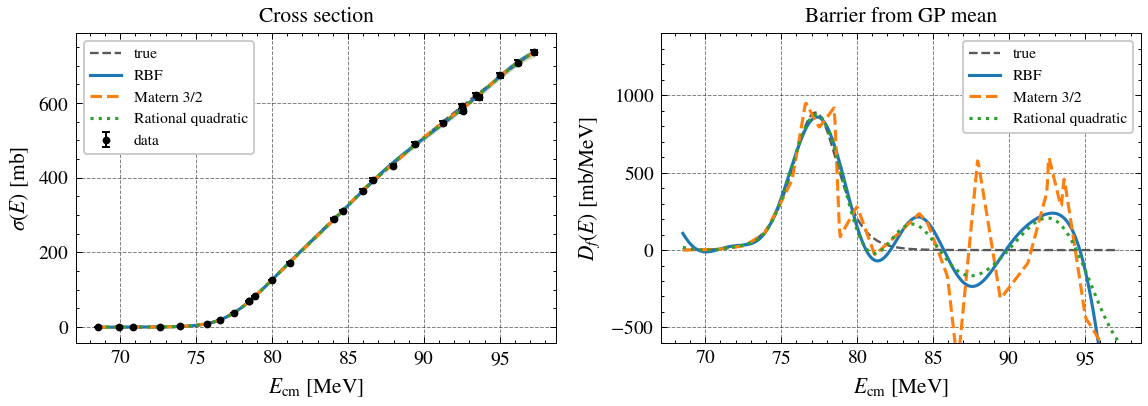

In [5]:
amp = max(np.var(Sigma_train), 1e-6)
ell0 = 2.0 * np.median(spacing)
kernels = {
    "RBF": ConstantKernel(amp, (1e-8, 1e9)) * RBF(ell0, (0.05, 20.0)),
    "Matern 3/2": ConstantKernel(amp, (1e-8, 1e9)) * Matern(ell0, (0.05, 20.0), nu=1.5),
    "Rational quadratic": ConstantKernel(amp, (1e-8, 1e9)) * RationalQuadratic(ell0, alpha=1.0),
}

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.1), sharex=True)
colors = ["tab:blue", "tab:orange", "tab:green"]
axes[0].errorbar(E_train, Sigma_train, yerr=Sigma_err_train, fmt="o", color="black", ms=3, capsize=2, label="data")
axes[0].plot(E_pred, Sigma_true, color="0.35", ls="--", lw=1.2, label="true")
axes[1].plot(E_pred, D_true, color="0.35", ls="--", lw=1.2, label="true")

for (name, kernel), color in zip(kernels.items(), colors):
    gp = fit_gp_model(E_train, Sigma_train, Sigma_err_train, kernel, n_restarts=3)
    print(f"{name}: {gp.kernel_}")
    plot_sigma_and_barrier(axes[0], axes[1], gp, name, color)

axes[0].set_title("Cross section")
axes[1].set_title("Barrier from GP mean")
axes[0].set_ylabel(r"$\sigma(E)$ [mb]")
axes[1].set_ylabel(r"$D_f(E)$ [mb/MeV]")
for ax in axes:
    ax.set_xlabel(r"$E_{\mathrm{cm}}$ [MeV]")
    ax.legend(frameon=True)
axes[1].set_ylim(-600, 1400)
fig.tight_layout()
fig.savefig(PLOT_DIR / "kernel_experiments_kernel_family_comparison.png", bbox_inches="tight")
plt.show()


## 3. Linear-space vs log-space training

The log-space model is a cleaner likelihood for positive, multiplicative data.
This final exploratory plot keeps the same RBF family and compares the fitted
cross section and its derivative in physical units.


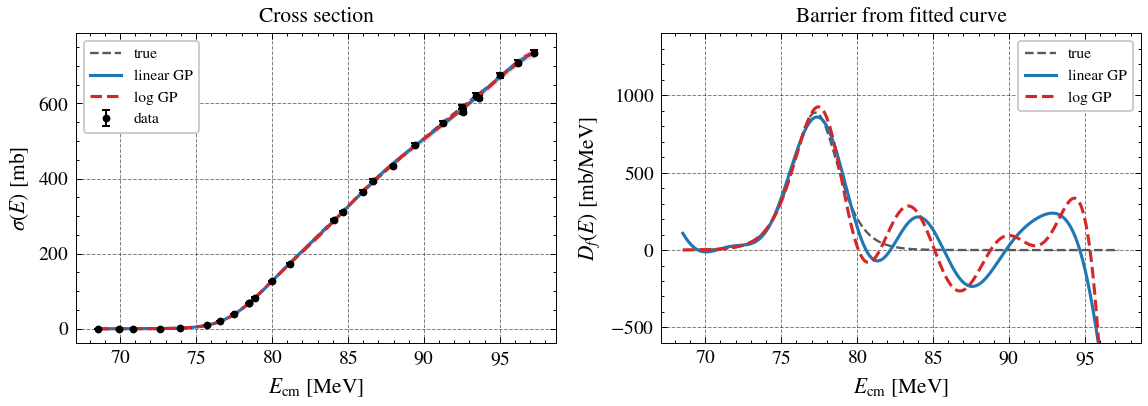

In [6]:
gp_linear = fit_gp_model(E_train, Sigma_train, Sigma_err_train, base_rbf(), space="linear", n_restarts=4)
gp_log = fit_gp_model(E_train, Sigma_train, Sigma_err_train, base_rbf(), space="log", n_restarts=4)

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.1), sharex=True)
axes[0].errorbar(E_train, Sigma_train, yerr=Sigma_err_train, fmt="o", color="black", ms=3, capsize=2, label="data")
axes[0].plot(E_pred, Sigma_true, color="0.35", ls="--", lw=1.2, label="true")
axes[1].plot(E_pred, D_true, color="0.35", ls="--", lw=1.2, label="true")
plot_sigma_and_barrier(axes[0], axes[1], gp_linear, "linear GP", "tab:blue", space="linear")
plot_sigma_and_barrier(axes[0], axes[1], gp_log, "log GP", "tab:red", space="log")

axes[0].set_title("Cross section")
axes[1].set_title("Barrier from fitted curve")
axes[0].set_ylabel(r"$\sigma(E)$ [mb]")
axes[1].set_ylabel(r"$D_f(E)$ [mb/MeV]")
for ax in axes:
    ax.set_xlabel(r"$E_{\mathrm{cm}}$ [MeV]")
    ax.legend(frameon=True)
axes[1].set_ylim(-600, 1400)
fig.tight_layout()
fig.savefig(PLOT_DIR / "kernel_experiments_linear_vs_log.png", bbox_inches="tight")
plt.show()


## Notes

The exploratory lesson is that cross-section interpolation quality and barrier
quality are not the same objective. Smooth-looking fits can hide very different
second derivatives, especially on irregular grids. For the thesis narrative, the
more detailed RBF contribution decomposition now lives in
`Ch2-0-Plots.ipynb`.
